# 02 - Long-term TRF on Dataset I (milestone 3)

`PROJECT_PLAN.md` §9.1-9.2 steps 1-2: Das preprocessing (Cz reference,
1-9 Hz, 32 Hz, z-score), the 15-band gammatone envelope, and mTRF-style ridge
TRFs (lags 0-400 ms) fitted over all 16 subjects' HRTF trials, separately
for attend-left and attend-right. Same code as `scripts/05_long_term_trf.py`
(`adr.trf.long_term`). Runtime: a few minutes (envelopes are cached under
`data/cache/envelopes`).

Set `SAVE = True` to overwrite `results/section_a/long_term_trf.{npz,png}`,
which milestone 4 reads.

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

import logging

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from adr.config import load_paths, package_versions, seed_everything

logging.basicConfig(level=logging.INFO, format="%(message)s", force=True)
pd.set_option("display.max_columns", 50, "display.width", 200)
paths = load_paths()
seed_everything()
package_versions()

{'python': '3.14.8',
 'numpy': '2.5.4',
 'scipy': '1.18.1',
 'pandas': '3.0.6',
 'mne': '1.13.2',
 'scikit-learn': '1.9.1',
 'lightgbm': '4.7.0',
 'xgboost': '3.4.2',
 'eelbrain': '0.43.0b0',
 'matplotlib': '3.11.2',
 'mne-icalabel': '0.10.0'}

In [2]:
from adr.trf import long_term

SAVE = False
result = long_term.run()
print(f"{result.n_trials} HRTF trials, {result.minutes:.1f} min total")
print(f"reference lag: {1000 * result.lags[result.reference_lag] / 32:.0f} ms")

160 HRTF trials, 616.5 min; reference lag 250 ms; held-out r 0.0178 (null -0.0004)


160 HRTF trials, 616.5 min total
reference lag: 250 ms


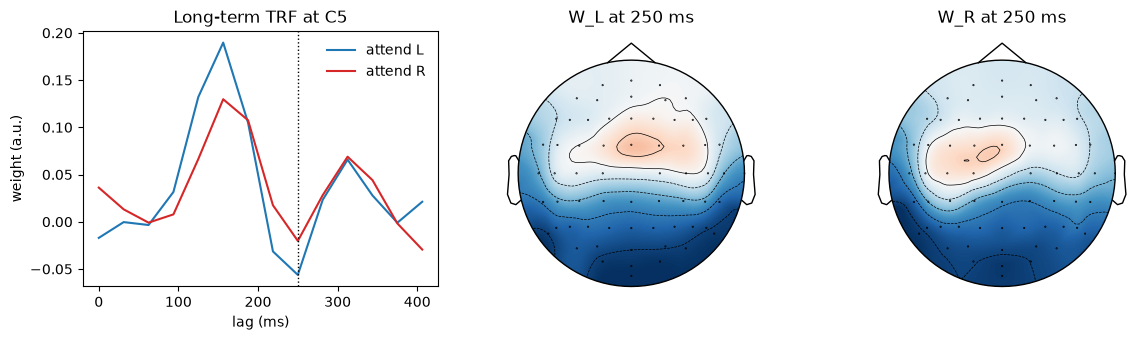

In [3]:
fig = long_term.plot(result)

## Is it a sensible TRF?

Prediction of held-out story parts (whole parts left out, the §9.4 grouping
rule) against a 60 s circularly shifted envelope.

In [4]:
summary = pd.DataFrame({
    "held-out r (mean over channels)": result.cv_r.mean(1),
    "shifted-envelope null": result.cv_r_null.mean(1),
})
print(summary.mean().round(4).to_string())
print("fraction of trials above their null:", (summary.iloc[:, 0] > summary.iloc[:, 1]).mean().round(2))
best = pd.Series(result.cv_r.mean(0), index=result.ch_names).sort_values(ascending=False)
best.head(10).round(4)

held-out r (mean over channels)    0.0178
shifted-envelope null             -0.0004
fraction of trials above their null: 0.88


P9     0.0385
Iz     0.0382
P10    0.0378
Oz     0.0348
O2     0.0330
O1     0.0326
PO8    0.0321
P7     0.0315
TP8    0.0313
POz    0.0305
dtype: float64

## Regularisation

lambda = 0.2 (mTRF convention) leaves this TRF essentially unregularised;
the long-term fit uses Das et al.'s rule (penalty = max |X'X|). The C5 time
course under several lambdas:

Text(0.5, 1.0, 'Attend-left TRF at C5 vs lambda')

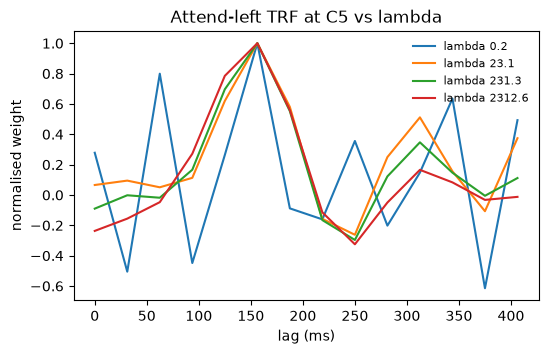

In [5]:
from adr.trf import ridge
from adr.config import load_yaml

cfg = load_yaml("section_a")["trf"]
trials, names = long_term.load_trials()
side = [t for t in trials if t.attended_ear == "L"]
xtx, xty = ridge.covariances([t.envelope for t in side], [t.eeg for t in side], result.lags)
das = ridge.das_lambda(xtx, 32)
c5 = names.index("C5")
plt.figure(figsize=(6, 3.5))
for lam in (0.2, 0.1 * das, das, 10 * das):
    w = ridge.solve(xtx, xty, lam, 32, result.lags).weights[:, c5]
    plt.plot(1000 * result.lags / 32, w / np.abs(w).max(), label=f"lambda {lam:.1f}")
plt.xlabel("lag (ms)"); plt.ylabel("normalised weight"); plt.legend(frameon=False, fontsize=8)
plt.title("Attend-left TRF at C5 vs lambda")

In [6]:
if SAVE:
    print(long_term.save(result))
    fig.savefig(paths["results"] / "section_a" / "long_term_trf.png", dpi=150)